<h1 align="center"> Tarea 1 - Web Content Mining
<h2 align="center">  Integrantes: Fernando Cáceres y Cristóbal Gajardo .
<h3 align="center"> IN5529 - Inteligencia Artificial Aplicada a la Web
<h3 align="center"> Primavera 2025

---

# Introducción

El objetivo de esta tarea es aplicar técnicas de Web Content Mining para obtener datos desde un sitio de recetas, procesarlos y analizarlos.  
Trabajaremos con recetas en español, lo que nos permitirá explorar el uso de herramientas de procesamiento de lenguaje natural (NLP) como SpaCy.  

Se espera demostrar que, a partir de páginas web no estructuradas, es posible construir un conjunto de datos organizado, listo para análisis y extracción de conocimiento.


# Librerias e instalaciones


En esta sección preparamos el entorno de Google Colab con las herramientas necesarias.  
- **Selenium**: permite automatizar la navegación y extracción de datos en sitios web.  
- **Chromedriver**: conecta Selenium con el navegador Chrome.  
- **SpaCy**: se usará para procesamiento de texto en español.  

Sin estas instalaciones, el scraping y el preprocesamiento no podrían ejecutarse.


In [ ]:
# Instalaciones
#!pip install selenium
!apt-get update
#!apt install chromium-chromedriver
import sys
sys.path.insert(0,'/usr/lib/chromium-browser/chromedriver')
!python -m spacy download es_core_news_md
#!pip install nltk

# Web Scraper
from selenium import webdriver
from selenium.common.exceptions import TimeoutException,  StaleElementReferenceException, NoSuchElementException
from selenium.webdriver.common.by import By
import re
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

# Librerías varias
import pandas as pd
import numpy as np
import json
import time
import random
import urllib

# Preprocesamiento
import re
import nltk
import string
nltk.download('punkt')
nltk.download('stopwords')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import strip_accents_ascii

# Lemmatization y Stemming
import spacy
from nltk import SnowballStemmer

# Data Mining
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

Hit:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:2 https://cli.github.com/packages stable InRelease
Hit:3 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease
Hit:5 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Hit:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu jammy InRelease
Hit:11 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# Proceso KDD
El proceso KDD (Knowledge Discovery in Databases) se compone de varias fases:  
1. Recolección de datos desde la web.  
2. Preprocesamiento y limpieza.  
3. Análisis exploratorio.  
4. Extracción de conocimiento.  

En las siguientes subsecciones se explicará cada fase con su respectivo código.


## Recolección de links con webscraper

Para comenzar, definimos las categorías de recetas que vamos a recolectar desde el sitio *cocina-tradicional.es*.  
Elegimos sólo 5 categorías (postres, carnes, pescado, aperitivo y pastas) de las 9 disponibles en la web, para que el scraping fuera más rápido y manejable; haciendo más enfasis en el proceso de recolección y KDD que en la calidad de los modelos.

Cada categoría contiene varias páginas, y en cada una hay múltiples recetas.  
Con Selenium recorremos estas páginas y guardamos los links a todas las recetas disponibles.



In [ ]:
# Categorías (cocina-tradicional.es). No terminan en .html (se escogieron sólo 5 categorias de las 9 disponibles para priorizar rapidez del scraping)
categories = [
    {"category": "postres",    "url": "https://cocina-tradicional.es/categorias/postres/",    "max_links": 120, "max_pages": 50},
    {"category": "carnes",     "url": "https://cocina-tradicional.es/categorias/carnes/",     "max_links": 120, "max_pages": 50},
    {"category": "pescado",    "url": "https://cocina-tradicional.es/categorias/pescado/",    "max_links": 120, "max_pages": 50},
    {"category": "aperitivo",  "url": "https://cocina-tradicional.es/categorias/aperitivo/",  "max_links": 120, "max_pages": 50},
    {"category": "pastas",     "url": "https://cocina-tradicional.es/categorias/pastas/",     "max_links": 120, "max_pages": 50},
]

# Configuración del WebDriver
chrome_options = webdriver.ChromeOptions()
chrome_options.add_argument('--headless')
chrome_options.add_argument('--no-sandbox')
chrome_options.add_argument('--disable-dev-shm-usage')


## Recolección de enlaces de recetas con Selenium

El objetivo de este bloque es **obtener todos los links de recetas** desde una categoría del sitio, recorriendo varias páginas de forma automática.  
El resultado es una **lista de URLs únicas**, que luego se usarán para extraer el contenido detallado de cada receta.

**Entradas:**
- `url_base`: URL de la categoría (ejemplo: "postres").  
- `max_links`: máximo de enlaces a recolectar.  
- `max_pages`: máximo de páginas a recorrer.  

**Salida:** lista de URLs de recetas (sin duplicados).
### 1) Configuración del navegador
- **Tamaño de ventana:** simula un navegador real.  
- **AutomationControlled:** evita que el sitio detecte Selenium.  
- **User-Agent:** se hace pasar por un navegador común.  
- **WebDriverWait (8 s):** espera explícita a que carguen los elementos.
### 2) Anti-detección
Se inyecta un script que hace que `navigator.webdriver` sea *undefined*, lo que dificulta que el sitio detecte la automatización. Esto ayuda a reducir bloqueos.
### 3) Extracción de enlaces en una página
- Se usan **selectores CSS** para localizar todas las tarjetas de recetas.  
- Se filtran enlaces que contengan `/recetas/` y el dominio correcto.  
- Se eliminan duplicados guardando los enlaces en un *set*.  

**Funciones auxiliares:**
- `current_page_num`: detecta el número de la página actual.  
- `find_next_url`: busca el link a la siguiente página (soporta `?page=N`, `/page/N/` y enlaces con texto como "siguiente").
### 4) Bucle principal
- Recorre las páginas hasta `max_pages` o hasta juntar `max_links`.  
- Llama a `extract_recipe_links()` en cada página y agrega solo enlaces nuevos.  
- Usa `find_next_url()` para moverse a la siguiente página; si no existe, termina el bucle.  
- Imprime un resumen final y siempre cierra el navegador con `driver.quit()`.  

**Buenas prácticas aplicadas:**
- Límites de enlaces y páginas → evitan loops largos.  
- Uso de `seen` → elimina duplicados.  
- Esperas explícitas → más estables que `sleep()`.  
- Mensajes de progreso → ayudan a depurar.


In [ ]:
# =========================
# LINKS: lista hrefs de recetas desde una categoría con paginación ?page=N o /page/N/
# =========================
import re
from urllib.parse import urljoin
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC

def links(url_base, max_links=200, max_pages=50):
    global chrome_options

    # Headless más estable
    chrome_options.add_argument("--window-size=1366,768")
    chrome_options.add_argument("--disable-blink-features=AutomationControlled")
    chrome_options.add_argument("--user-agent=Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 "
                                "(KHTML, like Gecko) Chrome/124.0.0.0 Safari/537.36")

    driver = webdriver.Chrome(options=chrome_options)
    wait = WebDriverWait(driver, 8)

    # Anti–detección simple
    try:
        driver.execute_cdp_cmd("Page.addScriptToEvaluateOnNewDocument", {
            "source": "Object.defineProperty(navigator, 'webdriver', {get: () => undefined});"
        })
    except:
        pass

    def accept_cookies():
        try:
            for b in driver.find_elements(By.XPATH,
                "//button[contains(translate(.,'ACEPT','acept'),'acept') or contains(.,'OK') or contains(.,'Ok')]"):
                if b.is_displayed() and b.is_enabled():
                    b.click()
                    break
        except:
            pass

    def extract_recipe_links():
        hrefs = set()
        # tarjetas/anchors hacia /recetas/
        for sel in [".mdl-card__actions a[href*='/recetas/']",
                    ".mdl-card a[href*='/recetas/']",
                    "main a[href*='/recetas/']",
                    "a[href*='/recetas/']"]:
            try:
                for a in driver.find_elements(By.CSS_SELECTOR, sel):
                    h = a.get_attribute("href") or ""
                    if "/recetas/" in h and "cocina-tradicional.es" in h:
                        hrefs.add(h)
            except:
                pass
            if hrefs:
                break
        return list(hrefs)

    def current_page_num(url):
        m = re.search(r"[?&]page=(\d+)", url)
        if m: return int(m.group(1))
        m = re.search(r"/page/(\d+)/", url)
        if m: return int(m.group(1))
        return 1

    def find_next_url(url_now):
        now = current_page_num(url_now)
        candidates = []

        # enlaces que parezcan de paginación
        for a in driver.find_elements(By.CSS_SELECTOR, "a[href]"):
            href = a.get_attribute("href") or ""
            # admitir ?page=N y /page/N/
            m = re.search(r"[?&]page=(\d+)", href) or re.search(r"/page/(\d+)/", href)
            if not m:
                # también probamos por texto "siguiente"
                txt = (a.text or "").strip().lower()
                if "siguiente" in txt or "›" in txt:
                    candidates.append((now + 1, urljoin(url_now, href)))
                continue
            n = int(m.group(1))
            if n > now:
                candidates.append((n, urljoin(url_now, href)))

        if not candidates:
            return None
        # nos quedamos con la página siguiente inmediata (>now y mínima)
        nmin, href = min(candidates, key=lambda t: t[0])
        return href if nmin > now else None

    try:
        data, seen = [], set()
        url = url_base.rstrip("/") + "/"

        for i in range(1, max_pages + 1):
            print(f"[links] page={i} url={url}")
            driver.get(url)
            accept_cookies()
            try:
                wait.until(EC.presence_of_all_elements_located((By.CSS_SELECTOR, "a[href]")))
            except:
                pass

            # 1) recolectar recetas de esta página
            nuevos = 0
            for h in extract_recipe_links():
                if h not in seen:
                    seen.add(h)
                    data.append(h)
                    nuevos += 1
                    if len(data) >= max_links:
                        print(f"\tSe han encontrado {len(data)} links")
                        return data

            # 2) buscar la URL de la página siguiente (soporta ?page=N y /page/N/)
            next_url = find_next_url(url)
            if not next_url:
                break
            url = next_url

        print(f"\tSe han encontrado {len(data)} links")
        return data
    finally:
        driver.quit()


## Parser de tiempos

Los tiempos de preparación vienen en distintos formatos como “2 horas”, “90 minutos” o “1h 30m”.  
Esto dificulta analizarlos, por lo que creamos una función que convierte cualquier texto de tiempo en un valor numérico en minutos.  

De esta manera, todos los tiempos quedan estandarizados y podemos calcular promedios y distribuciones de manera uniforme.

## Scraper

Este bloque visita cada URL de receta y extrae la información principal para guardarla en un formato homogéneo.  
La salida es un registro con: **título, tiempo de preparación (minutos normalizados y texto original), número de porciones, lista de ingredientes, pasos de la receta, categoría y fuente**.

**Funcionamiento:**
1. **Carga de página y espera:** se usa `WebDriverWait` para asegurar que los elementos estén disponibles antes de extraer datos.
2. **Título:** se busca primero en `div.name` y, si no aparece, en la etiqueta `<h1>`.
3. **Tiempo y porciones:** se recorren las secciones buscando encabezados con “tiempo” o “personas”.  
   - El tiempo se normaliza con `parse_time_to_minutes`.  
   - Las porciones se convierten a número entero.
4. **Ingredientes:** se localizan listas (`<ul>` o `<ol>`) que siguen al encabezado “INGREDIENTES”. Cada ítem se limpia y se agrega a la lista.
5. **Pasos:** se buscan en contenedores `.steps`.  
   - Si no existen, se usan *fallbacks* por encabezado “Pasos” o “Descripción”.  
   - Se descartan nodos irrelevantes con palabras como “email” o “escríbenos”.
6. **Robustez:** todo el proceso usa `try/except` para que si un campo falla no se detenga el scraping de la receta completa.  
   Se imprime el progreso, se contabilizan errores y al final se cierra el navegador.

**Además se incorporan:**
- Múltiples selectores y *fallbacks* → tolerancia a variaciones del HTML.  
- Normalización de tiempos en minutos → análisis uniforme.  
- Eliminación de duplicados y de texto irrelevante.  
- Uso de contadores de progreso y errores para monitorear la ejecución.

Este scraper transforma páginas web de recetas en un dataset limpio y estructurado, listo para análisis posterior.


In [ ]:
# ---------- Parser robusto de tiempo -> minutos ----------
def parse_time_to_minutes(value_text: str):
    """
    Convierte '5 Minutos', '2 Horas', '1 hora 30 minutos', '1 h 30 m',
    '1,5 horas' o '1.5 horas' a minutos (int). Devuelve None si no puede parsear.
    """
    if not value_text:
        return None
    s = value_text.strip().lower()
    s = (s.replace("á","a").replace("é","e").replace("í","i")
           .replace("ó","o").replace("ú","u"))

    # 1) 'X hora(s) Y minuto(s)' o 'X h Y m'
    m = re.search(r'(\d+)\s*h(?:ora)?s?\s*(?:y)?\s*(\d+)\s*m(?:inuto)?s?', s) \
        or re.search(r'(\d+)\s*ho?ra?s?\s*(?:y)?\s*(\d+)\s*mi?nuto?s?', s) \
        or re.search(r'(\d+)\s*h\s*(\d+)\s*m', s)
    if m:
        h = int(m.group(1)); mm = int(m.group(2))
        return h * 60 + mm

    # 2) horas con decimal: '1,5 horas' o '1.5 horas'
    m = re.search(r'(\d+(?:[.,]\d+)?)\s*h(?:ora)?s?', s)
    if m:
        h = float(m.group(1).replace(',', '.'))
        return int(round(h * 60))

    # 3) minutos con o sin plural (también decimal)
    m = re.search(r'(\d+(?:[.,]\d+)?)\s*m(?:inuto)?s?', s)
    if m:
        mm = float(m.group(1).replace(',', '.'))
        return int(round(mm))

    # 4) solo número → asumimos minutos
    m = re.search(r'^\s*(\d+(?:[.,]\d+)?)\s*$', s)
    if m:
        mm = float(m.group(1).replace(',', '.'))
        return int(round(mm))

    return None


# ---------- Scraper de recetas ----------
def scraper(links, data, category):
    """
    Extrae: title, preparationTime (min), rawTimeText, servings, ingredients, steps.
    Selecciona pasos desde '.steps .step .text' para evitar 'Email / Escríbenos'.
    """
    global chrome_options
    driver = webdriver.Chrome(options=chrome_options)
    wait = WebDriverWait(driver, 8)
    progress = 0
    errors = 0

    for link in links:
        print(f"\r\tLinks scrapeados: {progress} / {len(links)}", end="")
        try:
            driver.get(link)
            try:
                wait.until(EC.presence_of_all_elements_located((By.CSS_SELECTOR, ".content-section")))
            except:
                pass

            recipe = {"category": category, "source": link}

            # Título
            try:
                recipe["title"] = driver.find_element(
                    By.CSS_SELECTOR, "div.name.mdl-typography--text-left"
                ).text.strip()
            except:
                try:
                    recipe["title"] = driver.find_element(By.TAG_NAME, "h1").text.strip()
                except:
                    recipe["title"] = None

            # Tiempo / Personas
            preparationTime = None
            servings = None
            raw_time_text = None

            sections = driver.find_elements(By.CSS_SELECTOR, "div.content-section")
            for sec in sections:
                try:
                    label = sec.find_element(By.CSS_SELECTOR, "div.title").text.strip().lower()
                except:
                    continue

                # valor puede venir en .dificult o .name
                value = None
                for sel in ["div.dificult", "div.name"]:
                    try:
                        value = sec.find_element(By.CSS_SELECTOR, sel).get_attribute("textContent").strip()
                        if value:
                            break
                    except:
                        continue
                if not value:
                    continue

                if "tiempo" in label:
                    raw_time_text = value                      # guardamos el texto original
                    preparationTime = parse_time_to_minutes(value)
                elif "personas" in label:
                    m = re.search(r'(\d+)', value)
                    servings = int(m.group(1)) if m else None

            recipe["preparationTime"] = preparationTime   # minutos normalizados
            recipe["rawTimeText"] = raw_time_text         # útil para auditoría/debug
            recipe["servings"] = servings

            # Ingredientes
            ingredients = []
            ing_ul = driver.find_elements(
                By.XPATH,
                "//div[contains(@class,'title') and contains(translate(.,'INGREDIENTES','ingredientes'),'ingredientes')]/following::ul[1]/li"
            )
            if not ing_ul:
                ing_ul = driver.find_elements(
                    By.XPATH,
                    "//div[contains(@class,'title') and contains(translate(.,'INGREDIENTES','ingredientes'),'ingredientes')]/following::ol[1]/li"
                )
            for li in ing_ul:
                t = li.get_attribute("textContent").strip()
                if t:
                    ingredients.append(t)
            recipe["ingredients"] = ingredients

            # Pasos (preferente: contenedor .steps)
            steps = []
            for node in driver.find_elements(By.CSS_SELECTOR, "div.steps div.step div.text"):
                t = node.get_attribute("textContent").strip()
                tl = t.lower()
                if t and "email" not in tl and "escríbenos" not in tl and "escribenos" not in tl:
                    steps.append(t)

            # Fallback por encabezado "Pasos"
            if not steps:
                step_lis = driver.find_elements(
                    By.XPATH,
                    "//div[contains(@class,'title') and contains(translate(.,'PASOS','pasos'),'pasos')]/following::*[self::ol or self::ul][1]/li"
                )
                if step_lis:
                    for li in step_lis:
                        t = li.get_attribute("textContent").strip()
                        if t:
                            steps.append(t)
                else:
                    step_ps = driver.find_elements(
                        By.XPATH,
                        "//div[contains(@class,'title') and contains(translate(.,'PASOS','pasos'),'pasos')]/following::p[position()<=20]"
                    )
                    for p in step_ps:
                        t = p.get_attribute("textContent").strip()
                        tl = t.lower()
                        if t and "email" not in tl and "escríbenos" not in tl and "escribenos" not in tl:
                            steps.append(t)

            # Último fallback: 'Descripción'
            if not steps:
                desc_ps = driver.find_elements(
                    By.XPATH,
                    "//div[contains(@class,'title') and contains(translate(.,'DESCRIPCION','descripción'),'descripción')]/following::p[position()<=20]"
                )
                for p in desc_ps:
                    t = p.get_attribute("textContent").strip()
                    tl = t.lower()
                    if t and "email" not in tl and "escríbenos" not in tl and "escribenos" not in tl:
                        steps.append(t)

            recipe["steps"] = steps

            data.append(recipe)
            progress += 1

        except Exception:
            errors += 1
            continue

    print(f"\r\tLinks scrapeados: {progress} / {len(links)} (Errores: {errors})")
    print(f"\tSe han scrapeado {len(data)} recetas distintas")
    driver.quit()
    return data


## Función collect

La función `collect` integra todos los pasos anteriores:  
1. Recorre las categorías.  
2. Extrae los links de cada receta.  
3. Ingresa a cada receta y guarda datos como ingredientes, tiempo, dificultad y categoría.  

El resultado es una lista de diccionarios en Python con toda la información cruda.  
Este es el dataset base sobre el que trabajaremos.


In [ ]:
# Funcion collect
# Realiza el scrapeo de los links y el contenido de las recetas de forma secuencial
def collect(categories):
    data = list()
    for categoryDict in categories:
        #1) Leer parámetros de la categoría
        category = categoryDict["category"]
        url = categoryDict["url"]
        max_links = categoryDict.get("max_links", 100)   # límite de links por categoría
        max_pages = categoryDict.get("max_pages", 50)    # límite de páginas a recorrer

        print(f"Iniciando Scraper de la categoría `{category}`")

        #2) Recolección de enlaces de recetas (listado paginado)
        print('Scrapeando links de recetas...')
        collected_links = links(url, max_links=max_links, max_pages=max_pages)
        #asegurando que sean enlaces de receta y deduplicar
        collected_links = [h for h in dict.fromkeys(collected_links) if "/recetas/" in h]
        print(f"Listo. La cantidad de links disponibles para scrapear es: {len(collected_links)}")

        #3) Scrapeo del detalle de cada receta
        print('Scrapeando contenido de links...')
        data = scraper(collected_links, data, category)
        print(f"Scrapeo de la categoria `{category}` finalizado\n")
    return data


## Exportación de datos

Transformamos los datos en un DataFrame de Pandas para manipularlos más fácilmente.  
Además, los guardamos en un archivo JSON.  

Esto es útil porque, si queremos volver a trabajar con el dataset, no necesitamos correr el scraping de nuevo: simplemente cargamos el archivo guardado.


In [ ]:
# Scrapeamos y almacenamos los resultados en un .json
data = collect(categories)          # corre tus funciones links + scraper
db = pd.DataFrame(data)             # convierte a DataFrame para trabajar más cómodo
with open('recipes.json', 'w', encoding='utf-8') as file:
    db.to_json(file, force_ascii=False)   # guarda en JSON respetando acentos


Iniciando Scraper de la categoría `postres`
Scrapeando links de recetas...
[links] page=1 url=https://cocina-tradicional.es/categorias/postres/
[links] page=2 url=https://cocina-tradicional.es/categorias/postres/?page=2
[links] page=3 url=https://cocina-tradicional.es/categorias/postres/?page=3
	Se han encontrado 57 links
Listo. La cantidad de links disponibles para scrapear es: 57
Scrapeando contenido de links...
	Links scrapeados: 57 / 57 (Errores: 0)
	Se han scrapeado 57 recetas distintas
Scrapeo de la categoria `postres` finalizado

Iniciando Scraper de la categoría `carnes`
Scrapeando links de recetas...
[links] page=1 url=https://cocina-tradicional.es/categorias/carnes/
[links] page=2 url=https://cocina-tradicional.es/categorias/carnes/?page=2
[links] page=3 url=https://cocina-tradicional.es/categorias/carnes/?page=3
[links] page=4 url=https://cocina-tradicional.es/categorias/carnes/?page=4
	Se han encontrado 71 links
Listo. La cantidad de links disponibles para scrapear es: 71
S

## Visualización de una receta al azar

Para comprobar que los datos se recolectaron correctamente, mostramos una receta aleatoria del dataset.  
Esto nos permite verificar que se guardaron campos como título, ingredientes, tiempo y categoría.


In [ ]:
#visualizando receta al azar
n=random.randint(0,len(data))
db.iloc[n]

,218
category,pescado
source,https://cocina-tradicional.es/recetas/esgarraet/
title,Esgarraet
preparationTime,5.0
rawTimeText,alarm 5 Minutos
servings,3.0
ingredients,"[400 gramos de pimientos asados con su jugo, 8..."
steps,[El esgarraet es un plato tan sencillo que si ...


## Pre-procesamiento

El preprocesamiento busca limpiar y transformar los datos para que puedan analizarse.  
Algunos problemas encontrados fueron:  
- Tiempos en formatos distintos.  
- Ingredientes escritos de diferentes maneras.  
- Presencia de palabras irrelevantes (*stopwords*).  

Con SpaCy realizamos tokenización, eliminación de stopwords y lematización.  
Así logramos un texto más uniforme y útil para análisis de lenguaje natural.


In [ ]:
# Para subir el json y no correr el scraper de nuevo
from google.colab import files
uploaded = files.upload()


Saving recipes.json to recipes.json


In [ ]:
df = pd.read_json('recipes.json')

# Unimos los elementos de las listas de ingredientes y pasos
df["ingredients"] = df["ingredients"].map(lambda x: ", ".join(x) if isinstance(x, list) else str(x) if x is not None else "")
df["steps"]       = df["steps"].map(lambda x: ", ".join(x) if isinstance(x, list) else str(x) if x is not None else "")

# Creamos la variable de features seleccionando los datos a utilizar
df["recipe_content"] = (df["title"].fillna("") + df["ingredients"].fillna("") + df["steps"].fillna(""))


df["preparationTime"] = pd.to_numeric(df["preparationTime"], errors="coerce")

# (agregamos preparationTime para poder entrenar regresión más adelante)
df = df[["recipe_content", "category", "preparationTime"]].copy()

# Visualizamos las features
display(df.head())


,recipe_content,category,preparationTime
0,Empanadillas de manzana12 obleas de empanadi...,postres,30.0
1,Palmeritas de hojaldre2 láminas de hojaldre ...,postres,20.0
2,"Email, Escríbenos",postres,NaN
3,Fresas con helado de nata y chocolate200 gr...,postres,5.0
4,"Hojuelas lisas6 huevos, 600 gramos de harin...",postres,90.0


In [ ]:
# Seleccionamos las categorías a utilizar
selected_categories = ['postres', 'carnes', 'pastas', 'aperitivo', 'pescado']
df = df[df['category'].isin(selected_categories)]

# Revisamos qué categorías quedaron
df['category'].unique()


array(['postres', 'carnes', 'pescado', 'aperitivo', 'pastas'],
      dtype=object)

In [ ]:
# Revisamos los valores de alguna fila
n=random.randint(0,len(df))
df["recipe_content"].iloc[n]

'Filetes de pescada en salsa de tomate800 gramos de filetes de pescada, 1  cebolla, 1  pimiento rojo, 3  tomates rojos grandes, 100 gramos de harina, 200 mililitro de aceite de oliva, al gusto de salVamos a realizar hoy una receta que resulta económica y muy rica. Para ello en primer lugar, cortaremos nuestros filetes de pescada sin piel ni espinas en trozos de unos 5 centímetros. Los salamos al gusto y los enharinamos muy ligeramente., En una sartén, ponemos el aceite y vamos friendo los trozos de pescada pero muy ligeramente. Sólo vuelta y vuelta para que se doren por fuera. Así no se reseca el pescado., Conforme los vamos dorando, los vamos sacando a una bandeja con papel absorvente., Por otro lado, en una sartén de base ancha, echamos un chorreón de aceite de oliva y cuando esté caliente, añadimos la cebolla y el pimiento rojo picado con un poquito de sal para que se vaya pochando antes. A fuego medio esperamos a que la cebolla y el pimiento se ablanden., A continuación añadimos el

In [ ]:
# Creamos una función para limpiar tags HTML, saltos de línea, espacios innecesarios
def clean_string(string):
  if string == None:
    return string

  html_tags = re.compile('<.*?>|&([a-z0-9]+|#[0-9]{1,6}|#x[0-9a-f]{1,6});')
  spaces = re.compile('\s\s+')

  string = re.sub(html_tags, " ", string)
  string = re.sub(spaces, " ", string)
  string = string.replace("\t", " ")
  string = string.replace(" ,", ",")
  string = string.strip(" ").strip("\n")
  string = string.replace("\\n", " ").replace("\n", " ")

  return string

<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-1346139409.py:7: SyntaxWarning: invalid escape sequence '\s'
  spaces = re.compile('\s\s+')


In [ ]:
# Limpiamos los strings del dataset

#por seacaso
df = df.dropna(subset=["recipe_content"]).reset_index(drop=True)

df["recipe_content"] = df["recipe_content"].map(clean_string)

In [ ]:
df["recipe_content"].iloc[20]

'Tarta de galletas con chocolate1 paquete (3 envases) galletas cuadradas maría, 1 litro de leche, 1.5 sobre flan "el niño", 5 cucharadas soperas de colmadas de chocolate en polvo a la taza, 3 cucharadas soperas de azúcar, al gusto de canela (opcional), 2 cucharadas soperas de coñacPara realizar nuestra tarta, prepararemos en primer lugar el chocolate y las natillas. Para hacer el chocolate, tomaremos medio litro de leche del que separaremos media taza para diluir las cucharadas de cacao en polvo., Mientras vamos calentando el resto del medio litro de leche en un cazo. Cuando tenemos el cacao bien disuelto, lo añadimos a la leche que estamos calentando y removemos a fuego bajo hasta que espese. Lo reservamos., Para las natillas, cogemos otro medio litro de leche, del que apartamos igualmente media taza para disolver el sobre de flan el niño. El resto del medio litro lo ponemos en un cazo junto con el azúcar a calentar. Añadimos el flan disuelto y removemos igualmente a fuego bajo hasta 

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
# Eliminamos acentos
df['recipe_content'] = df['recipe_content'].apply(lambda x: strip_accents_ascii(x) if x is not None else x)

# Transformamos las letras a minusculas
df['recipe_content'] = df['recipe_content'].str.lower()

# Eliminamos las puntuaciones
regex = re.compile('[%s]' % re.escape(string.punctuation))
df['recipe_content'] = df['recipe_content'].apply(lambda x: regex.sub('', x) if x is not None else x)

# Eliminamos los espacios extra
df['recipe_content'] = df['recipe_content'].apply(lambda x: ' '.join(x.split()) if x is not None else x)

# Eliminar las stopwords
spanish_stopwords = stopwords.words('spanish')
df['recipe_content'] = df['recipe_content'].apply(lambda x: ' '.join([i for i in word_tokenize(x) if i not in spanish_stopwords]) if x is not None else x)

In [ ]:
df["recipe_content"].iloc[20]

'tarta galletas chocolate1 paquete 3 envases galletas cuadradas maria 1 litro leche 15 flan nino 5 cucharadas soperas colmadas chocolate polvo taza 3 cucharadas soperas azucar gusto canela opcional 2 cucharadas soperas conacpara realizar tarta prepararemos primer lugar chocolate natillas hacer chocolate tomaremos medio litro leche separaremos media taza diluir cucharadas cacao polvo mientras vamos calentando resto medio litro leche cazo cacao bien disuelto anadimos leche calentando removemos fuego bajo espese reservamos natillas cogemos medio litro leche apartamos igualmente media taza disolver flan nino resto medio litro ponemos cazo junto azucar calentar anadimos flan disuelto removemos igualmente fuego bajo espese lado ponemos leche plato hondo anadimos conac vamos mojando galletas empapen demasiado vamos colocando bandeja bandejas queremos ir formando tartas ahora cubrimos capa natillas ve foto continuacion ponemos capa galletas remojadas cubrimos chocolate asi vamos formando capas

## Transformación

Una vez que los datos fueron limpiados, aplicamos una fase de **transformación** para preparar el texto para poder hacer analisis estadisiticos.  
El objetivo es **reducir la variabilidad** en las palabras y dejar solo la información relevante.

- **Lematización:** convierte las palabras a su forma base o diccionario  
  (ejemplo: *“cocinando”*, *“cocinado”* → *“cocinar”*).  
- **Stemming:** recorta las palabras a su raíz, sin importar que no siempre sea una palabra real  
  (ejemplo: *“cocinar”*, *“cocinando”* → *“cocin”*).


**hacer esto nos da paso:**
- agrupar palabras que tienen el mismo significado aunque estén escritas de forma distinta.  
- Reducir el tamaño del vocabulario y hace más eficiente el análisis.  
- Preparar los datos para cálculos de frecuencia (repeticion), nubes de palabras, o modelos de clasificación (data mining).



In [ ]:
# 1) Lemmatization
nlp = spacy.load('es_core_news_md')

def to_lemmas(text):
    if not text:
        return ""
    doc = nlp(text)
    return " ".join(tok.lemma_ for tok in doc if tok.lemma_.strip())

df["text_lemma"] = df["recipe_content"].apply(to_lemmas)

In [ ]:
# 2) Stemming
stemmer = SnowballStemmer("spanish")
def to_stems(text):
    if not text:
        return ""
    return " ".join(stemmer.stem(t) for t in word_tokenize(text))

df["text_stem"] = df["recipe_content"].apply(to_stems)

In [ ]:
df.head(1)

,recipe_content,category,preparationTime,text_lemma,text_stem
0,empanadillas manzana12 obleas empanadillas 4 m...,postres,30.0,empanadilla manzana12 oblea empanadillas 4 man...,empanadill manzana12 oble empanadill 4 manzan ...


In [ ]:
# Bow manual
# Un BoW transforma cada documento en un vector de dimensión V (número de palabras únicas en el corpus).
# Doc -> vector de dim(V) // v: # palabras únicas
# En cada posición j se cuenta cuántas veces aparece el término j en el documento.
# Así queda una matriz D x V (docs x vocabulario)

from collections import Counter
import numpy as np

def build_vocab(docs):
    """
    docs: df
    construyendo vocabulario a partir de lista de documentos
      token -> índice
    """
    vocab = {}
    for doc in docs:
        for tok in doc.split():
            if tok not in vocab:
                vocab[tok] = len(vocab)   # asignar un índice único
    rev_vocab = [None]*len(vocab)
    for t,i in vocab.items():
        rev_vocab[i] = t
    return vocab, rev_vocab

def bow_matrix(docs, vocab):
    """
    docs: lista de documentos
    vocab: diccionario token -> índice
    Devuelve matriz BoW: counts de cada token en cada documento
    """
    V = len(vocab)                # tamaño del vocabulario
    X = np.zeros((len(docs), V), dtype=np.float32)
    for i, doc in enumerate(docs):
        cnt = Counter(doc.split())  # contar tokens en documento i
        for tok, c in cnt.items():
            j = vocab.get(tok)
            if j is not None:
                X[i, j] = c        # guardar la frecuencia absoluta
    return X

# Apllicando con lemma y stem
docs_lemma = df["text_lemma"].tolist()
vocab_lemma, rev_vocab_lemma = build_vocab(docs_lemma)
X_bow_lemma = bow_matrix(docs_lemma, vocab_lemma)

docs_stem = df["text_stem"].tolist()
vocab_stem, rev_vocab_stem = build_vocab(docs_stem)
X_bow_stem = bow_matrix(docs_stem, vocab_stem)

print("BoW lemma:", X_bow_lemma.shape)
print("BoW stem:", X_bow_stem.shape)


BoW lemma: (299, 3012)
BoW stem: (299, 2139)


In [ ]:
# tf-idf manual
# La idea es ponderar cada término según que tanto aparece en el doc y que tan raro es en todo el corpus
# Fórmula idf usada: df(t) = log( (1 + N) / (1 + df(t)) ) + 1
#     N = número de documentos
#     df(t) = número de documentos que contienen el término t
# tf-idf(d,t) = tf(d,t) * idf(t)
# al final se normaliza por su norma l2 para evitar que docs largos dominen
def tfidf_from_bow(X_counts):
    """
    X_counts: matriz BoW (docs x vocabulario)
    return: matriz TF-IDF normalizada, vector idf
    """
    d, V = X_counts.shape
    # df = en cuántos documentos aparece cada término
    df_vec = np.count_nonzero(X_counts > 0, axis=0)

    # cálculo idf
    idf = np.log((1.0 + d) / (1.0 + df_vec)) + 1.0

    # multiplicar BoW por idf
    X_tfidf = X_counts * idf[np.newaxis, :]

    # normalización L2 fila a fila
    norms = np.linalg.norm(X_tfidf, axis=1, keepdims=True)
    norms[norms == 0.0] = 1.0
    X_tfidf = X_tfidf / norms
    return X_tfidf, idf

# Calculando para lemma y stem
X_tfidf_lemma, idf_lemma = tfidf_from_bow(X_bow_lemma)
X_tfidf_stem, idf_stem = tfidf_from_bow(X_bow_stem)

print("TF-IDF lemma:", X_tfidf_lemma.shape)
print("TF-IDF stem:", X_tfidf_stem.shape)


TF-IDF lemma: (299, 3012)
TF-IDF stem: (299, 2139)


In [ ]:
# Comparacion
# CountVectorizer y TfidfTransformer implementan internamente lo mismo.
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer

def space_tokenizer(s):
    return s.split()

# lemmas
cv_lemma = CountVectorizer(tokenizer=space_tokenizer, lowercase=False, token_pattern=None)
X_cv_lemma = cv_lemma.fit_transform(docs_lemma)

tfidf_tr_lemma = TfidfTransformer(use_idf=True, norm='l2')
X_cv_tfidf_lemma = tfidf_tr_lemma.fit_transform(X_cv_lemma)

print("— LEMMA —")
print("Vocab manual:", len(vocab_lemma), " | Vocab sklearn:", len(cv_lemma.vocabulary_))
print("BoW shapes:", X_bow_lemma.shape, "vs", X_cv_lemma.shape)
print("TF-IDF shapes:", X_tfidf_lemma.shape, "vs", X_cv_tfidf_lemma.shape)

# stems
cv_stem = CountVectorizer(tokenizer=space_tokenizer, lowercase=False, token_pattern=None)
X_cv_stem = cv_stem.fit_transform(docs_stem)

tfidf_tr_stem = TfidfTransformer(use_idf=True, norm='l2')
X_cv_tfidf_stem = tfidf_tr_stem.fit_transform(X_cv_stem)

print("\n— STEM —")
print("Vocab manual:", len(vocab_stem), " | Vocab sklearn:", len(cv_stem.vocabulary_))
print("BoW shapes:", X_bow_stem.shape, "vs", X_cv_stem.shape)
print("TF-IDF shapes:", X_tfidf_stem.shape, "vs", X_cv_tfidf_stem.shape)


— LEMMA —
Vocab manual: 3012  | Vocab sklearn: 3012
BoW shapes: (299, 3012) vs (299, 3012)
TF-IDF shapes: (299, 3012) vs (299, 3012)

— STEM —
Vocab manual: 2139  | Vocab sklearn: 2139
BoW shapes: (299, 2139) vs (299, 2139)
TF-IDF shapes: (299, 2139) vs (299, 2139)


## Data Mining

En esta etapa aplicamos técnicas de **minería de datos** para construir modelos predictivos a partir del dataset transformado.  
Se trabajó tanto con representaciones de texto **lematizadas** como con **stemming** para comparar el desempeño de ambos enfoques.

**1) Regresión**  
- Objetivo: predecir el **tiempo de preparación** de una receta en minutos.  
- Se entrenó un modelo con el vector de características TF-IDF y la variable `preparationTime` como salida.  
- Se dividieron los datos en entrenamiento (80%) y prueba (20%) para evaluar la capacidad de predicción.

**2) Clasificación**  
- Objetivo: predecir la **categoría de la receta** (por ejemplo, postres, carnes, etc.) a partir de su descripción.  
- Se aplicó un balanceo de clases con **RandomOverSampler** para evitar el sesgo hacia las categorías con más datos.  
- Se entrenó el clasificador y se evaluó su desempeño sobre el conjunto de prueba.




In [ ]:
# Clasificación de categoria con RF para lema
from imblearn.over_sampling import RandomOverSampler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X = X_tfidf_lemma
y_cat = df["category"]

ros = RandomOverSampler(random_state=8)
X_res, y_res = ros.fit_resample(X, y_cat)

Xtr_lemma_clf, Xte_lemma_clf, ytr_lemma_clf, yte_lemma_clf = train_test_split(
    X_res, y_res, train_size=0.8, test_size=0.2, stratify=y_res, random_state=5529
)

rf_lemma_clf = RandomForestClassifier(random_state=8)
rf_lemma_clf.fit(Xtr_lemma_clf, ytr_lemma_clf)
pred_lemma_clf = rf_lemma_clf.predict(Xte_lemma_clf)


In [ ]:
# Clasificación de categoria con RF para stem
X = X_tfidf_stem
y_cat = df["category"]

ros = RandomOverSampler(random_state=8)
X_res, y_res = ros.fit_resample(X, y_cat)

Xtr_stem_clf, Xte_stem_clf, ytr_stem_clf, yte_stem_clf = train_test_split(
    X_res, y_res, train_size=0.8, test_size=0.2, stratify=y_res, random_state=5529
)

rf_stem_clf = RandomForestClassifier(random_state=8)
rf_stem_clf.fit(Xtr_stem_clf, ytr_stem_clf)
pred_stem_clf = rf_stem_clf.predict(Xte_stem_clf)


In [ ]:
# Regresión para el tiempo de preparación para lema
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import pandas as pd

X = X_tfidf_lemma
y_time = pd.to_numeric(df["preparationTime"], errors="coerce").fillna(df["preparationTime"].median())

Xtr_lemma_reg, Xte_lemma_reg, ytr_lemma_reg, yte_lemma_reg = train_test_split(
    X, y_time, train_size=0.8, test_size=0.2, random_state=8
)

rf_lemma_reg = RandomForestRegressor(random_state=8)
rf_lemma_reg.fit(Xtr_lemma_reg, ytr_lemma_reg)
pred_lemma_time = rf_lemma_reg.predict(Xte_lemma_reg)


In [ ]:
# Regresión para el tiempo de preparación para stem
X = X_tfidf_stem
y_time = pd.to_numeric(df["preparationTime"], errors="coerce").fillna(df["preparationTime"].median())

Xtr_stem_reg, Xte_stem_reg, ytr_stem_reg, yte_stem_reg = train_test_split(
    X, y_time, train_size=0.8, test_size=0.2, random_state=8
)

rf_stem_reg = RandomForestRegressor(random_state=8)
rf_stem_reg.fit(Xtr_stem_reg, ytr_stem_reg)
pred_stem_time = rf_stem_reg.predict(Xte_stem_reg)


## Evaluación
## Evaluación de modelos

Después de entrenar los modelos de clasificación, es necesario **evaluar su desempeño**.  
En esta sección utilizamos métricas estándar de *machine learning* para medir qué tan bien los modelos predicen la categoría de las recetas.

**Métricas aplicadas:**
- `classification_report`: entrega precisión (*precision*), cobertura (*recall*) y puntaje F1 para cada categoría.
- `confusion_matrix`: muestra, en forma de tabla, cuántas recetas fueron clasificadas correctamente y cuántas fueron confundidas con otra categoría.

**Visualización:**
- Se grafican las matrices de confusión con `seaborn.heatmap` para facilitar la interpretación.  
- Se comparan las dos variantes de modelo definidas anteriormente:  
  - Con **lematización**.  
  - Con **stemming**.



EVALUACIÓN CLASIFICACIÓN (LEMMA)
              precision    recall  f1-score   support

   aperitivo       0.63      0.63      0.63        19
      carnes       0.93      0.72      0.81        18
      pastas       0.78      1.00      0.88        18
     pescado       0.68      0.72      0.70        18
     postres       1.00      0.89      0.94        19

    accuracy                           0.79        92
   macro avg       0.81      0.79      0.79        92
weighted avg       0.81      0.79      0.79        92

Matriz de confusión:


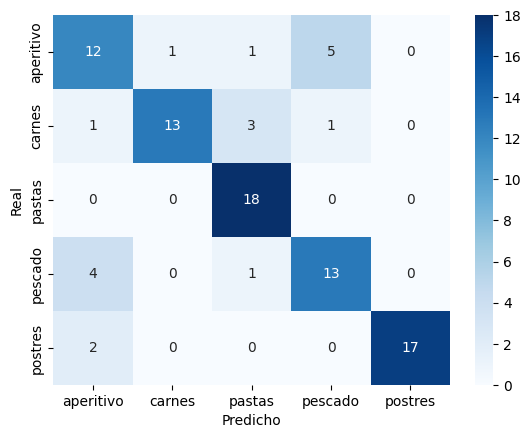

EVALUACIÓN CLASIFICACIÓN (STEM)
              precision    recall  f1-score   support

   aperitivo       0.64      0.74      0.68        19
      carnes       0.92      0.67      0.77        18
      pastas       0.78      1.00      0.88        18
     pescado       0.71      0.67      0.69        18
     postres       1.00      0.89      0.94        19

    accuracy                           0.79        92
   macro avg       0.81      0.79      0.79        92
weighted avg       0.81      0.79      0.79        92

Matriz de confusión:


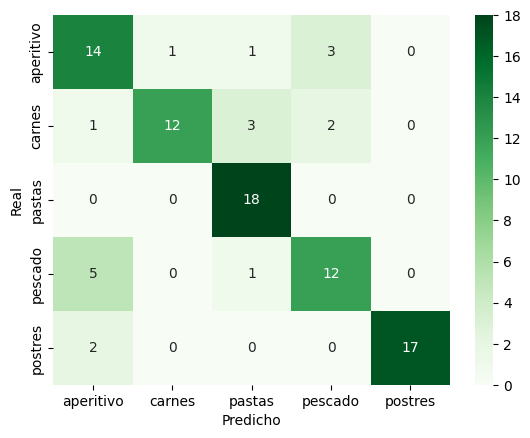

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("========================================")
print("EVALUACIÓN CLASIFICACIÓN (LEMMA)")
print("========================================")
print(classification_report(yte_lemma_clf, pred_lemma_clf))
print("Matriz de confusión:")
cm = confusion_matrix(yte_lemma_clf, pred_lemma_clf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=rf_lemma_clf.classes_,
            yticklabels=rf_lemma_clf.classes_)
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()


print("========================================")
print("EVALUACIÓN CLASIFICACIÓN (STEM)")
print("========================================")
print(classification_report(yte_stem_clf, pred_stem_clf))
print("Matriz de confusión:")
cm = confusion_matrix(yte_stem_clf, pred_stem_clf)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=rf_stem_clf.classes_,
            yticklabels=rf_stem_clf.classes_)
plt.xlabel("Predicho")
plt.ylabel("Real")
plt.show()


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

def eval_reg(y_true, y_pred, nombre="Modelo"):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{nombre} → MAE: {mae:.2f} | RMSE: {rmse:.2f} | R²: {r2:.3f}")


print("EVALUACIÓN REGRESIÓN (LEMMA)")
eval_reg(yte_lemma_reg, pred_lemma_time, "RandomForest (Lemma)")

print("\n========================================")
print("EVALUACIÓN REGRESIÓN (STEM)")
eval_reg(yte_stem_reg, pred_stem_time, "RandomForest (Stem)")


EVALUACIÓN REGRESIÓN (LEMMA)
RandomForest (Lemma) → MAE: 31.87 | RMSE: 57.27 | R²: 0.306

EVALUACIÓN REGRESIÓN (STEM)
RandomForest (Stem) → MAE: 32.21 | RMSE: 59.20 | R²: 0.258


# Conclusiones



A lo largo de este trabajo aplicamos el proceso KDD para recolectar, limpiar, transformar y analizar recetas de cocina desde la web.  
El pipeline completo incluyó scraping, preprocesamiento, transformación del texto, minería de datos y evaluación de modelos.

**Principales hallazgos:**
- El scraping permitió obtener un dataset estructurado de recetas con información como título, tiempo, ingredientes, pasos y categoría.
- El preprocesamiento y la transformación (tokenización, stopwords, lematización y stemming) fueron claves para reducir la variabilidad del lenguaje y preparar los datos para análisis.
- En la etapa de minería de datos:
  - Los modelos de **clasificación** (Random Forest) alcanzaron una **accuracy cercana al 79%** en ambos enfoques (lemma y stem).  
  - Algunas categorías como *postres* y *pastas* tuvieron un desempeño muy alto (F1 > 0.88), mientras que *aperitivos* y *pescados* resultaron más difíciles de predecir.
  - Las **matrices de confusión** mostraron que los errores comunes provienen de confusiones entre categorías con descripciones similares.
- En los modelos de **regresión**, el ajuste fue más limitado:  
  - Con lematización se obtuvo R² ≈ 0.30, y con stemming R² ≈ 0.25.  
  - Esto indica que predecir el tiempo exacto de preparación es una tarea más compleja que clasificar categorías.

**Comparación lemma vs stem:**
- Ambos enfoques tuvieron resultados similares en clasificación.  
- Lematización mostró un ligero mejor rendimiento en regresión, pero la diferencia no es muy significativa.

**Reflexión final:**
La tarea evidenció cómo a partir de información no estructurada en páginas web es posible generar un dataset organizado y aplicar técnicas de minería de datos para extraer conocimiento.  
Si bien los modelos de clasificación mostraron un desempeño satisfactorio, los de regresión presentan un mayor desafío y podrían mejorarse con más datos o atributos adicionales (ej. dificultad de la receta o número de pasos) o afinando la intepretacion de catagorias incluyendo mas de estas lo cual va de la mano con el trade-off con el costo computacional del procesamiento de datos.
